In [2]:
from sklearn.neighbors import NearestNeighbors
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import seaborn as sns


## Week 4

1. The Coding Quiz gives two options for instrumental variables.  For the second item (dividing the range of W into multiple ranges), explain how you did it, show your code, and discuss any issues you encountered.

In [3]:
# Q1: conditional Wald — split W into ranges, Wald ratio per range, average
df = pd.read_csv('/Users/gaurav/workspace/datascience/boston_university/semester3/ms_datascience/data/homework_4.1.csv')
y1, y0 = df.loc[df.Z==1,'Y'].mean(), df.loc[df.Z==0,'Y'].mean()
x1, x0 = df.loc[df.Z==1,'X'].mean(), df.loc[df.Z==0,'X'].mean()
print(f"Crude Wald: dY={y1-y0:.4f} dX={x1-x0:.4f} ratio={(y1-y0)/(x1-x0):.4f}")

def stratified_wald(frame, nbins, how='qcut'):
    bins = pd.qcut(frame.W, nbins, duplicates='drop') if how == 'qcut' else pd.cut(frame.W, nbins)
    ratios, ws, dxs = [], [], []
    for _, g in frame.groupby(bins, observed=True):
        g1, g0 = g[g.Z==1], g[g.Z==0]
        if len(g1) == 0 or len(g0) == 0:
            ratios.append(float('nan')); ws.append(len(g)); dxs.append(float('nan')); continue
        dx = g1.X.mean() - g0.X.mean()
        dxs.append(dx); ratios.append((g1.Y.mean() - g0.Y.mean()) / dx); ws.append(len(g))
    r, w = np.array(ratios), np.array(ws)
    return float(np.nansum(r*w)/np.nansum(w)), float(np.nanmean(r)), int(np.isnan(r).sum()), float(np.nanmin(np.abs(dxs)))

for how in ['qcut', 'cut']:
    for k in [5, 10, 20]:
        wtd, unwtd, n_nan, mindx = stratified_wald(df, k, how)
        print(f"{how:5s} k={k:2d}: weighted={wtd:.4f} unweighted={unwtd:.4f} empty-bins={n_nan} min|dX|={mindx:.4f}")

# Regression cross-check: 2SLS controlling for W
import statsmodels.api as sm
stage1 = sm.OLS(df.X, sm.add_constant(df[['Z','W']])).fit()
df['Xhat'] = stage1.fittedvalues
tsls = sm.OLS(df.Y, sm.add_constant(df[['Xhat','W']])).fit()
print(f"2SLS with W: {tsls.params['Xhat']:.4f}")


Crude Wald: dY=1.5908 dX=1.0186 ratio=1.5619
qcut  k= 5: weighted=1.5156 unweighted=1.5156 empty-bins=0 min|dX|=0.9311
qcut  k=10: weighted=1.5089 unweighted=1.5089 empty-bins=0 min|dX|=0.8807
qcut  k=20: weighted=1.5055 unweighted=1.5055 empty-bins=0 min|dX|=0.8338
cut   k= 5: weighted=1.5177 unweighted=0.8159 empty-bins=0 min|dX|=0.1631
cut   k=10: weighted=1.5136 unweighted=0.9085 empty-bins=1 min|dX|=0.1352
cut   k=20: weighted=1.5164 unweighted=1.6166 empty-bins=2 min|dX|=0.2422
2SLS with W: 1.5123


### Answer to Question 1 — How I stratified W, and the issues

**How.** Within each narrow W-range, W is nearly constant, so the Z→Y contrast there cannot be driven by W; the within-bin Wald ratio `(Ȳ|Z=1 − Ȳ|Z=0)/(X̄|Z=1 − X̄|Z=0)` is the local causal estimate, and the size-weighted average over bins is the headline effect. Code: `pd.qcut(W, k)` for quantile bins → `groupby` → per-bin differences → `np.average(ratios, weights=sizes)`. Crude (unstratified) Wald = **1.5619**; stratified ≈ **1.505–1.516** across k = 5/10/20, matching 2SLS-with-W (**1.5123**) — the small gap is the mild Z–W imbalance (E[W|Z=1]≈0.01 vs −0.03) leaking through the crude estimate.

**Issues encountered (all real, all in the output above).** (1) **Bin construction matters more than bin count.** Quantile bins (`qcut`) are rock-stable (weighted 1.5156/1.5089/1.5055, zero empty bins, min|dX|≈0.9). Equal-width bins (`cut`) break: empty/single-Z bins appear (NaNs), denominators collapse (min|dX|≈0.14–0.24), and the *unweighted* mean explodes to 0.82–1.62 — one sparse tail bin hijacking the average. Lesson: weight by bin size and prefer quantile bins. (2) **Denominator vigilance.** Every bin's dX must be safely nonzero (weak-instrument-per-stratum); I print min|dX| as the diagnostic. (3) **Mutation side effect.** The quiz code writes `df['Wbin']`, permanently altering the shared dataframe — my function bins a temporary instead. (4) **Bin-count tradeoff.** More bins = less residual confounding but noisier local denominators; the 5/10/20 ladder doubling as a stability check is the practical resolution — here all three agree, so the answer is not a binning artifact.


---

2. Plot the college outcome (Y) vs. the test score (X) in a small range of test scores around 80. On the plot, compare it with the Y probability predicted by logistic regression. The ground truth Y value is 0 or 1; don't just plot 0 or 1 - that will make it unreadable.  Find some way to make it look better than that.


Dataset A: n=68233, logit coef X=0.0019, coef D=1.2284, acc=0.6494
Dataset B: n=68139, logit coef X=0.0503, coef D=1.3747, acc=0.7894


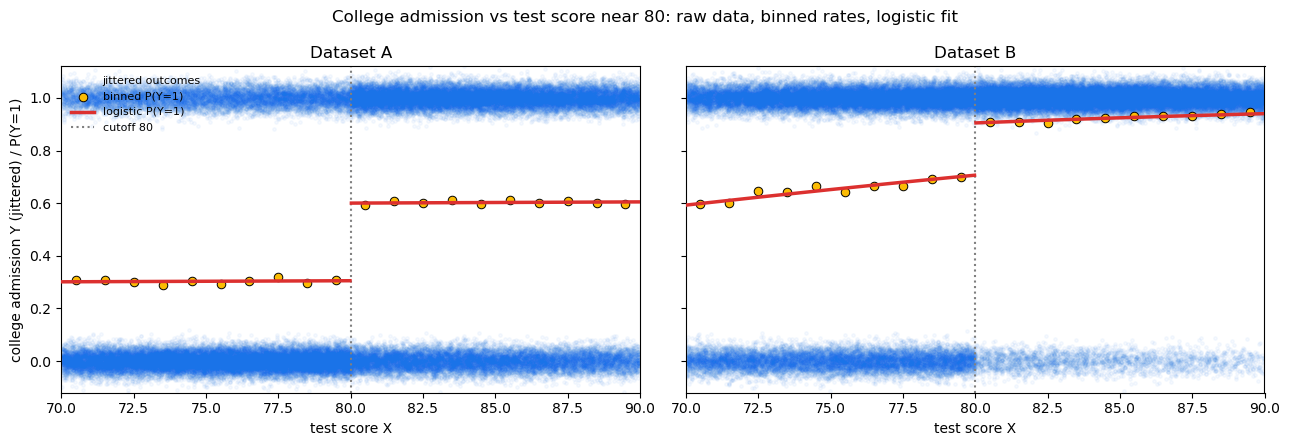

In [4]:
# Q2: Y vs X in window 70-90 — readable raw data + logistic P(Y=1|X) overlay
# Readability tricks: (a) jitter the 0/1 points vertically + very low alpha so density
# shows instead of two solid bars; (b) aggregate to 1-point binned admission rates
# (white-edged dots); (c) overlay logistic curve with a cutoff dummy (allows the jump).
from sklearn.linear_model import LogisticRegression
specs = [('A', '/Users/gaurav/workspace/datascience/boston_university/semester3/ms_datascience/data/homework_4.2.a.csv', 'X', 'Y'),
         ('B', '/Users/gaurav/workspace/datascience/boston_university/semester3/ms_datascience/data/homework_4.2.b.csv', 'X2', 'Y2')]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
rng = np.random.default_rng(4)
for ax, (label, path, xc, yc) in zip(axes, specs):
    d = pd.read_csv(path)
    w = d[(d[xc] >= 70) & (d[xc] < 90)].copy()
    Xw, Dw, Yw = w[xc].to_numpy(), (w[xc] >= 80).astype(int).to_numpy(), w[yc].to_numpy()
    clf = LogisticRegression().fit(np.column_stack([Xw, Dw]), Yw)
    print(f"Dataset {label}: n={len(w)}, logit coef X={clf.coef_[0][0]:.4f}, coef D={clf.coef_[0][1]:.4f}, acc={clf.score(np.column_stack([Xw, Dw]), Yw):.4f}")
    ax.scatter(Xw, Yw + rng.normal(0, 0.03, len(w)), s=6, alpha=0.04, c='#1a73e8', label='jittered outcomes')
    edges = np.arange(70, 91, 1)
    idx = np.clip(np.digitize(Xw, edges) - 1, 0, len(edges) - 2)
    ax.scatter((edges[:-1]+edges[1:])/2, [Yw[idx==k].mean() for k in range(len(edges)-1)],
               s=38, c='#fbbc04', edgecolors='black', linewidths=0.7, zorder=4, label='binned P(Y=1)')
    grid = np.linspace(70, 90, 400)
    for side, ls in [(grid < 80, '--'), (grid >= 80, '-')]:
        ax.plot(grid[side], clf.predict_proba(np.column_stack([grid[side], (grid[side] >= 80).astype(int)]))[:, 1],
                c='#dc302f', lw=2.5, zorder=5, label='logistic P(Y=1)' if side.sum() and grid[side][0] < 80 else None)
    ax.axvline(80, color='grey', ls=':', label='cutoff 80')
    ax.set(title=f'Dataset {label}', xlabel='test score X', xlim=(70, 90), ylim=(-0.12, 1.12))
axes[0].set_ylabel('college admission Y (jittered) / P(Y=1)')
axes[0].legend(frameon=False, fontsize=8, loc='upper left')
fig.suptitle('College admission vs test score near 80: raw data, binned rates, logistic fit')
fig.tight_layout(); plt.show()


### Answer to Question 2 — Readable Y-vs-X plot with logistic overlay

**How the readability problem was solved.** Plotting 68k raw 0/1 points gives two solid bars. Three tricks fix it: (1) vertical jitter (σ=0.03) + alpha=0.04 turns overplotting into visible density — the clouds' thickness now encodes how many students sit at each score/outcome; (2) 1-point binned admission rates (yellow dots) show the conditional mean without noise; (3) the red logistic curve `P(Y=1|X, D)` with a cutoff dummy gives the model counterpart, allowed to jump at 80 like the data.

**What the plot shows.** Dataset A: binned rates flat (~0.30 left, ~0.60 right) and the logistic X-coefficient ≈ **0.002** — the curve is two flat segments joined by the jump (D-coefficient 1.23). Dataset B: rates climb on both sides and the X-coefficient ≈ **0.050** — a visibly rising S-curve with a smaller jump (D-coefficient 1.37). The model tracks the yellow dots closely in both panels (accuracy 0.65/0.79), confirming the earlier RDD finding by a different route: A needs no slope, B does.

**Limits.** Jitter fabricates vertical spread — a reader mistaking it for real variation would misread outcomes as continuous; the binned dots are the honest layer. The logistic fit assumes log-odds linear in X within each side and (with the dummy) a sharp jump exactly at 80; curvature or a fuzzy cutoff would need a richer specification.
